# Continuum S/N mask visualisation

Shows what `src/02_continuum_mask.py` does to one galaxy, as a single row of three panels:

- **(a) Continuum S/N.** The mask keeps spaxels with finite flux and error, error > 0, flux > 0 and continuum S/N ≥ 3. The contour marks the mask edge.
- **(b) Raw Hα flux.** The summed-flux map from `data/fits/sami_dr3_Halpha_maps/`, with the same contour on top.
- **(c) Masked Hα flux.** Only the spaxels inside the mask are kept, which is what Gini, Asymmetry and Clumpiness are measured on. (b) and (c) share one colour scale, so the only difference is the removed spaxels (grey).

The mask is built with the pipeline's own functions (`src/utils/masking.py`), and the result is checked against the saved file in `data/masked/halpha/`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from astropy.io import fits

here = Path.cwd().resolve()
PIPELINE_ROOT = next(p for p in [here, *here.parents] if (p / "src" / "utils" / "paths.py").exists())
sys.path.insert(0, str(PIPELINE_ROOT))

from src.utils.halpha_map import BACKGROUND_COLOR, find_halpha_fits
from src.utils.io import read_masked_halpha, read_sami_halpha_layers
from src.utils.masking import apply_mask_2d, make_continuum_mask
from src.utils.paths import MASKED_HALPHA_DIR, OUTPUTS_DIR, RAW_CONT_DIR

OUT_FIGURE_DIR = OUTPUTS_DIR / "ch2" / "figures"

In [2]:
CATID = 611002          # Below-MS example galaxy, also used in the other Ch. 2 figures
SN_CUT = 3.0            # same as SN_CUT in src/02_continuum_mask.py
HALPHA_LAYER = "sum"    # summed-flux slice, the one the metrics use
PLATE_SCALE = 0.5       # arcsec per spaxel
SCALE_BAR_ARCSEC = 5.0

CONTOUR_COLOR = "magenta"
FLUX_LABEL = r"H$\alpha$ flux [$10^{-16}$ erg s$^{-1}$ cm$^{-2}$ spaxel$^{-1}$]"

In [3]:
# Continuum map -> S/N and mask, using the pipeline's own functions
cont_path = sorted(RAW_CONT_DIR.glob(f"{CATID}_*_HALPHA_cont_map_default.fits"))[0]
with fits.open(cont_path) as hdul:
    cont_flux = np.array(hdul[0].data, dtype=float)
    cont_err = np.array(hdul[1].data, dtype=float)
mask, sn_map = make_continuum_mask(cont_flux, cont_err, sn_cut=SN_CUT)

# Raw Halpha (summed slice) and the masked version
flux_layers, _, _, _ = read_sami_halpha_layers(str(find_halpha_fits(CATID)))
raw_ha = np.nan_to_num(flux_layers[HALPHA_LAYER], nan=0.0, posinf=0.0, neginf=0.0)
masked_ha = apply_mask_2d(raw_ha, mask)

# Check against the file 02_continuum_mask.py actually saved
saved_path = sorted(MASKED_HALPHA_DIR.glob(f"{CATID}_*_Halpha_masked.fits"))[0]
saved_flux, _ = read_masked_halpha(str(saved_path))
assert np.allclose(masked_ha, np.nan_to_num(saved_flux[1]), rtol=1e-5, atol=0), "Mismatch with saved masked map"

n_raw = int(np.sum(raw_ha != 0))
n_kept = int(np.sum(masked_ha != 0))
flux_removed = 1 - masked_ha.sum() / raw_ha.sum()
print(f"CATID {CATID}: kept {n_kept} / {n_raw} Halpha spaxels, {flux_removed:.1%} of Halpha flux removed")
print(f"Matches {saved_path.name}")

CATID 611002: kept 89 / 565 Halpha spaxels, 36.4% of Halpha flux removed
Matches 611002_A_Halpha_masked.fits


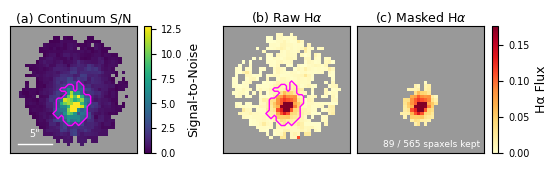

In [15]:
def _show_map(ax, data, cmap, vmin, vmax):
    # Zeros and non-finite values are shown as the grey no-data background
    shown = np.where(np.isfinite(data) & (data != 0), data, np.nan)
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad(BACKGROUND_COLOR)
    im = ax.imshow(shown, origin="lower", cmap=cm, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    return im

def draw_mask_edge(ax):
    ax.contour(mask.astype(float), levels=[0.5], colors=CONTOUR_COLOR, linewidths=1.0)

def view_window(margin_px=2):
    # Square window centred on the galaxy (all spaxels with any continuum or
    # Halpha data), used for all three panels so they show the same region
    footprint = (raw_ha != 0) | (np.isfinite(sn_map) & (sn_map > 0))
    ys, xs = np.nonzero(footprint)
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    half = max(ys.max() - ys.min(), xs.max() - xs.min()) / 2 + margin_px
    return (cx - half - 0.5, cx + half + 0.5), (cy - half - 0.5, cy + half + 0.5)


XLIM, YLIM = view_window()


def show_map(ax_, data, cmap, vmin, vmax):
    im = _show_map(ax_, data, cmap, vmin, vmax)
    ax_.set_xlim(XLIM)
    ax_.set_ylim(YLIM)
    return im


def add_scale_bar(ax):
    length_px = SCALE_BAR_ARCSEC / PLATE_SCALE
    width, height = XLIM[1] - XLIM[0], YLIM[1] - YLIM[0]
    x0, y0 = XLIM[0] + 0.06 * width, YLIM[0] + 0.07 * height
    ax.plot([x0, x0 + length_px], [y0, y0], color="white", lw=1)
    ax.text(x0 + length_px / 2, y0 + 1.5, f'{SCALE_BAR_ARCSEC:g}"', color="white",
            ha="center", va="bottom", fontsize=7)


def panel_label(ax, text):
    ax.set_title(text, fontsize=9, pad=3)


fig = plt.figure(figsize=(6.3, 2.3))
gs = gridspec.GridSpec(1, 6, figure=fig, width_ratios=[1, 0.05, 0.45, 1, 1, 0.05], wspace=0.1)
ax_sn, cax_sn = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax_raw, ax_masked, cax_ha = fig.add_subplot(gs[3]), fig.add_subplot(gs[4]), fig.add_subplot(gs[5])

# (a) continuum S/N with the mask edge
sn_shown = np.where(np.isfinite(sn_map) & (sn_map > 0), sn_map, np.nan)
im_sn = show_map(ax_sn, sn_shown, "viridis", 0, np.nanpercentile(sn_shown, 99))
draw_mask_edge(ax_sn)
add_scale_bar(ax_sn)
panel_label(ax_sn, "(a) Continuum S/N")
cb = fig.colorbar(im_sn, cax=cax_sn)
cb.set_label("Signal-to-Noise", fontsize=9)
cb.ax.tick_params(labelsize=7)

# (b) raw and (c) masked Halpha on one shared colour scale
vmax = np.percentile(raw_ha[raw_ha > 0], 99)
show_map(ax_raw, raw_ha, "YlOrRd", 0, vmax)
draw_mask_edge(ax_raw)
panel_label(ax_raw, r"(b) Raw H$\alpha$")

im_ha = show_map(ax_masked, masked_ha, "YlOrRd", 0, vmax)
panel_label(ax_masked, r"(c) Masked H$\alpha$")
ax_masked.text(0.97, 0.03, f"{n_kept} / {n_raw} spaxels kept", transform=ax_masked.transAxes,
               ha="right", va="bottom", fontsize=6.5, color="white")

cb = fig.colorbar(im_ha, cax=cax_ha)
cb.set_label(f"Hα Flux", fontsize=9)
cb.ax.tick_params(labelsize=7)

# Match each colourbar's height to the square image panels
fig.canvas.draw()
for cax, ax in [(cax_sn, ax_sn), (cax_ha, ax_masked)]:
    img_box, cbar_box = ax.get_position(), cax.get_position()
    cax.set_position([cbar_box.x0, img_box.y0, cbar_box.width, img_box.height])

plt.show()

In [16]:
OUT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
out_stem = OUT_FIGURE_DIR / "masking_visual"
fig.savefig(f"{out_stem}.png", dpi=300, bbox_inches="tight")
print(f"Saved -> {out_stem}.png")

Saved -> /Users/sophiesinclair/Desktop/sami copy/outputs/ch2/figures/masking_visual.png
